## Apply MPL to LTEE data

In [1]:
import numpy as np 
import pandas as pd

from scipy.linalg import solve
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
import colorsys

from scipy.stats import expon, genpareto

In [2]:
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Estimate fitness from MPL and no linkage method

In [3]:
#MPL parameters
gamma = 5
delta = 3

#Mutation rates from Zanini et al. with states {A,C,G,T,-} - rate per day assumed to be rate per generation
mutation_matrix = np.array(([0,1.2e-6,5.4e-6,6e-7,1e-9],[3e-6,0,5e-7,1.1e-5,1e-9],[1.5e-5,6e-8,0,1e-6,1e-9],[1.8e-6,8e-6,2e-6,0,1e-9],[1e-9,1e-9,1e-9,1e-9,0])) #mu_{ij} is mutation rate from i to j per locus per generation (diagonal is zero)
mutation_matrix

array([[0.0e+00, 1.2e-06, 5.4e-06, 6.0e-07, 1.0e-09],
       [3.0e-06, 0.0e+00, 5.0e-07, 1.1e-05, 1.0e-09],
       [1.5e-05, 6.0e-08, 0.0e+00, 1.0e-06, 1.0e-09],
       [1.8e-06, 8.0e-06, 2.0e-06, 0.0e+00, 1.0e-09],
       [1.0e-09, 1.0e-09, 1.0e-09, 1.0e-09, 0.0e+00]])

In [4]:
def MPL_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix, gamma, delta):

    ######################################              MPL algorithm               ######################################

    # x contains allele frequencies and has shape (num_mutations x number_time_points)
    # positions is a vector containing the genome position of each mutation and has length num_mutations
    # allele_numbers is a vector containing the allele present at that genome position (converted to integer) and has length num_mutations
    # time_between_samples is a vector of length number_time_points - 1, with the kth element being t_{k+1} - t_{k}
    # mutation_matrix has shape number_alleles*number_alleles, and must have a zero diagonal
    # gamma is a scalar: the regularisation parameter
    # delta is a scalar: the window size for estimating the covariance
    
    num_muts = x.shape[0]
    number_time_points = x.shape[1]


    ################### Calculate estimated integrated covariance matrix ################### 


    #Actual diagonal elements (variances)
    variances = x[:, :-1] - (x[:, :-1] ** 2) #estimated covariance only up to penultimate time point
    variances = np.maximum(variances, 0) #Ensure all variances are positive (precision limit might make them slightly negative)

    #Calculate E matrix (without multiplicative factor)
    dxdx = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        dxdx[:,:,k] = np.outer(x[:,k+1]-x[:,k], x[:,k+1]-x[:,k])

    E = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        for l in np.intersect1d(np.arange(k-delta,k+delta+1),np.arange(number_time_points-1)):
            E[:,:,k] += dxdx[:,:,l]


    #Calculate estimated covariance matrix using normalisation of non-diagonal terms
    E_diag = np.swapaxes(np.diagonal(E),0,1)
    E_prod = E_diag[:, None, :] * E_diag[None, :, :]
    var_prod = variances[:, None, :] * variances[None, :, :]
    scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
    C_est = E * scale_factor
    C_est[np.arange(num_muts),np.arange(num_muts),:] = variances[np.arange(num_muts),:] #Diagonal (variances)


    #Estimate x_ij from estimated covariances
    x_ij_est = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        x_ij_est[:,:,k] = C_est[:,:,k] + np.outer(x[:,k],x[:,k]) 

    #Integrate estimated covariance matrix
    C_est_int = np.zeros((num_muts,num_muts))

    for k in range(number_time_points-2): #Non-diagonal elements
        C_est_int += time_between_samples[k]*((x_ij_est[:,:,k+1] + x_ij_est[:,:,k])/2 -
                                    (np.outer(x[:,k],x[:,k])+np.outer(x[:,k+1],x[:,k+1]))/3 - 
                                    (np.outer(x[:,k],x[:,k+1])+np.outer(x[:,k+1],x[:,k]))/6)
            
    diag = np.zeros(num_muts) #Diagonal elements
    for k in range(number_time_points-2):
        diag += time_between_samples[k]*((x[:,k+1] + x[:,k])/2 -
                                    (np.square(x[:,k+1]) + np.square(x[:,k]) + np.multiply(x[:,k+1],x[:,k]))/3)
    np.fill_diagonal(C_est_int,diag)




    ################### Calculate integrated flux vector ###################

    #Collect loci of mutations
    unique_positions = list(set(positions))
    unique_pos_idx = []
    for p in positions:
        unique_pos_idx.append((unique_positions == p).argmax())

    #Put frequencies in matrix with shape (unique_positions x num_alleles x number_time_points)
    x_matrix = np.zeros((len(unique_positions),5,number_time_points))
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        x_matrix[p,a,:] = x[i,:]

    #Calculate flux at each time point
    mu_fl_matrix = np.zeros_like(x_matrix) 
    for k in range(number_time_points): 
        mu_fl_matrix[:,:,k] = np.matmul(x_matrix[:,:,k],mutation_matrix) - (mutation_matrix.sum(axis=1))*x_matrix[:,:,k]
        
    #Piecewise linear integration of flux
    mu_fl_matrix_int = np.zeros((len(unique_positions),5)) 
    for k in range(number_time_points-1): 
        mu_fl_matrix_int += time_between_samples[k]*(mu_fl_matrix[:,:,k]+mu_fl_matrix[:,:,k+1])/2 

    #Convert flux to vector with shape (num_muts x number_time_points)
    mu_fl_vector = np.zeros(num_muts)
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        mu_fl_vector[i] = mu_fl_matrix_int[p,a]



    ################### Solve for selection coefficients ###################
    s = solve(C_est_int + gamma*np.identity(num_muts), x[:,-1] - x[:,0] - mu_fl_vector, assume_a='gen')


    return s, C_est_int

In [5]:
def no_linkage_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix):

    ######################################              No linkage method algorithm               ######################################

    # x contains allele frequencies and has shape (num_mutations x number_time_points)
    # positions is a vector containing the genome position of each mutation and has length num_mutations
    # allele_numbers is a vector containing the allele present at that genome position (converted to integer) and has length num_mutations
    # time_between_samples is a vector of length number_time_points - 1, with the kth element being t_{k+1} - t_{k}
    # mutation_matrix has shape number_alleles*number_alleles, and must have a zero diagonal

    
    num_muts = x.shape[0]
    number_time_points = x.shape[1]


    ################### Calculate integrated variances ################### 

    #Variances at each time point
    variances = np.zeros((num_muts,number_time_points))
    for i in range(num_muts):
        variances[i,:] = x[i,:] - np.multiply(x[i,:],x[i,:])
        variances[i,:] = np.where(variances[i,:]>0,variances[i,:],0) #Ensure all variances are positive (precision limit might make them slightly negative)
    variances = variances[:,:-1] #estimated covariance only up to penultimate time point


    #Piecewise linear integration 
    variances_int = np.zeros(num_muts)
    for k in range(number_time_points-1):
        variances_int += time_between_samples[k]*((x[:,k+1] + x[:,k])/2 -
                                    (np.square(x[:,k+1]) + np.square(x[:,k]) + np.multiply(x[:,k+1],x[:,k]))/3)



    ################### Calculate integrated flux vector ###################

    #Collect loci of mutations
    unique_positions = list(set(positions))
    unique_pos_idx = []
    for p in positions:
        unique_pos_idx.append((unique_positions == p).argmax())

    #Put frequencies in matrix with shape (unique_positions x num_alleles x number_time_points)
    x_matrix = np.zeros((len(unique_positions),5,number_time_points))
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        x_matrix[p,a,:] = x[i,:]

    #Calculate flux at each time point
    mu_fl_matrix = np.zeros_like(x_matrix) 
    for k in range(number_time_points): 
        mu_fl_matrix[:,:,k] = np.matmul(x_matrix[:,:,k],mutation_matrix) - (mutation_matrix.sum(axis=1))*x_matrix[:,:,k]
        
    #Piecewise linear integration of flux
    mu_fl_matrix_int = np.zeros((len(unique_positions),5)) 
    for k in range(number_time_points-1): 
        mu_fl_matrix_int += time_between_samples[k]*(mu_fl_matrix[:,:,k]+mu_fl_matrix[:,:,k+1])/2 

    #Convert flux to vector with shape (num_muts x number_time_points)
    mu_fl_vector = np.zeros(num_muts)
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        mu_fl_vector[i] = mu_fl_matrix_int[p,a]



    ################### Solve for selection coefficients ###################
    s = (x[:,-1] - x[:,0] - mu_fl_vector)/variances_int


    return s, variances_int

In [6]:
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
dfs = []
covariances = []

for line in [13,14,15,16]:
    data_line = data[data['line'] == line].copy()

    #Get data in the form required for MPL
    x = data_line[np.arange(0,511,10)].astype(float).values

    time_between_samples = 10*3.5 + np.zeros(x.shape[1]-1) #in units of generations (assumed to be 3.5 generations per transfer - one per day)

    allele_numbers = data_line['new']
    allele_numbers = np.where(allele_numbers=='A',0,allele_numbers)
    allele_numbers = np.where(allele_numbers=='C',1,allele_numbers)
    allele_numbers = np.where(allele_numbers=='G',2,allele_numbers)
    allele_numbers = np.where(allele_numbers=='T',3,allele_numbers)
    allele_numbers = np.where(allele_numbers=='-',4,allele_numbers)
    allele_numbers = np.array([0 if "i" in str(new).lower() else new for new in allele_numbers])
    allele_numbers = np.array([4 if "d" in str(new).lower() else new for new in allele_numbers])
    allele_numbers = allele_numbers.astype(int)

    data_line['MPL pos'] = data_line['pos']
    insertion_positions = np.arange(1+data_line['pos'].max(),1+data_line['pos'].max()+len(data_line[data_line['type']=='insertion'])/2).astype(int)
    deletion_positions = np.arange(1+insertion_positions.max(),1+insertion_positions.max()+len(data_line[data_line['type']=='deletion'])/2).astype(int)
    data_line.loc[(data_line['type']=='insertion') & (data_line['details']=='consensus'),'MPL pos'] = insertion_positions
    data_line.loc[(data_line['type']=='insertion') & (data_line['details']!='consensus'),'MPL pos'] = insertion_positions
    data_line.loc[(data_line['type']=='deletion') & (data_line['details']=='consensus'),'MPL pos'] = deletion_positions
    data_line.loc[(data_line['type']=='deletion') & (data_line['details']!='consensus'),'MPL pos'] = deletion_positions
    positions = data_line['MPL pos'].values.astype(int)
    data_line = data_line.drop(columns=['MPL pos'])

    #Apply MPL to each line
    s, C_int = MPL_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix, gamma, delta)
    data_line['s'] = s
    std = np.sqrt(np.diag(np.linalg.inv(C_int + gamma*np.identity(s.shape[0])))/data_line['Mean pop size'].astype(float))  #Calculate standard deviation
    data_line['std'] = std

    #Apply no linkage method to each line
    s, var_int = no_linkage_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix)
    data_line['s no linkage'] = s
    std = np.sqrt(1/(var_int*data_line['Mean pop size'].astype(float).values))  #Calculate standard deviation
    data_line['std no linkage'] = std

    #Normalise based on consensus mutations
    for p in data_line['pos'].unique():
        data_p = data_line[(data_line['pos']==p) & (data_line['type']=='substitution')].copy()
        consensus_s = data_p.loc[data_p['details']=='consensus','s'].values
        data_p['s'] -= consensus_s
        consensus_s_no_linkage = data_p.loc[data_p['details']=='consensus','s no linkage'].values
        data_p['s no linkage'] -= consensus_s_no_linkage
        dfs.append(data_p[data_p['details']!='consensus']) #remove consensus rows

    for type in ['insertion','deletion']:
        data_type = data_line[(data_line['type']==type)].copy()
        s_consensus = data_type.loc[data_line['details'] == 'consensus','s']
        data_type.loc[data_line['details'] != 'consensus','s'] -= s_consensus.values
        s_consensus_no_linkage = data_type.loc[data_line['details'] == 'consensus','s no linkage']
        data_type.loc[data_line['details'] != 'consensus','s no linkage'] -= s_consensus_no_linkage.values
        dfs.append(data_type[data_type['details']!='consensus']) #remove consensus rows

    #Store covariances for non-consensus mutations
    non_con_idx = data_line.reset_index().index[data_line['details'] !='consensus'].to_numpy()
    covariances.append(C_int[np.ix_(non_con_idx,non_con_idx)])
    
    
data = pd.concat(dfs)

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_43415/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_43415/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_43415/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_43415/3058894517.py:39: RuntimeWarn

In [7]:
data[data['muttype']=='Nonsense']

,pos,new,line,type,gene,muttype,details,Max frequency,Length,Mean pop size,...,460,470,480,490,500,510,s,std,s no linkage,std no linkage
3726,5610,A,13,substitution,Vpr,Nonsense,17: W->stopcodon,0.23706,48,16677.3125,...,0.005983,0.004248,0.001803,0.002196,0.002098,0.001333,0.010794,0.003173,-0.000649,0.000891
3734,5611,A,13,substitution,Vpr,Nonsense,17: W->stopcodon,0.09083,30,16483.433333,...,0.023039,0.007631,0.016915,0.003275,0.002739,0.002203,-0.006861,0.003313,-0.001948,0.001540
3887,5670,A,13,substitution,Vpr,Nonsense,37: W->stopcodon,0.628934,27,13947.074074,...,0.421541,0.575,0.489337,0.628934,0.535244,0.551927,0.026798,0.003496,0.010885,0.000860
3891,5671,A,13,substitution,Vpr,Nonsense,37: W->stopcodon,0.560357,40,16197.25,...,0.106525,0.052645,0.087117,0.116368,0.124475,0.098098,0.040758,0.003224,0.001315,0.000739
3937,5687,T,13,substitution,Vpr,Nonsense,43: Q->stopcodon,0.063327,14,15870.571429,...,0.0,0.001595,0.0,0.0,0.0,0.0,-0.013754,0.003396,-0.004824,0.002597
3970,5707,A,13,substitution,Vpr,Nonsense,49: Y->stopcodon,0.243466,20,13591.5,...,0.112705,0.167791,0.173689,0.243466,0.187975,0.133009,-0.025392,0.003642,0.010782,0.001012
3991,5718,A,13,substitution,Vpr,Nonsense,53: W->stopcodon,0.091201,48,16580.5625,...,0.003023,0.007927,0.003518,0.009583,0.004856,0.002869,0.014912,0.003348,-0.002135,0.001627
4349,6125,A,13,substitution,Vpu,Nonsense,21: W->stopcodon,0.066318,19,27119.684211,...,0.001176,0.001124,0.001072,0.0,0.0,0.0,-0.014123,0.002654,-0.010256,0.002617
5979,8081,A,13,substitution,Env,Nonsense,620: W->stopcodon,0.051259,51,28433.039216,...,0.016087,0.01403,0.016509,0.014524,0.012348,0.008867,-0.015211,0.002566,-0.001751,0.001294
6742,8787,A,13,substitution,Nef,Nonsense,startcodon->K,0.31073,18,28038.611111,...,0.0,0.0,0.0,0.0,0.0,0.0,-0.007461,0.002540,-0.000646,0.000993


## Save results

In [8]:
#Save all of data as a .pkl
data.to_pickle(out_path + '/mutation_time_series_with_fitness.pkl')

#Save data without time series as a .csv
data.drop(columns=np.arange(0,511,10)).to_csv(out_path + '/mutations_with_fitness.csv', index=False)

#Save covariances as 
np.savez_compressed(out_path + '/estimated_covariances.npz', 
    line13=covariances[0], 
    line14=covariances[1], 
    line15=covariances[2], 
    line16=covariances[3])

## Plot time series

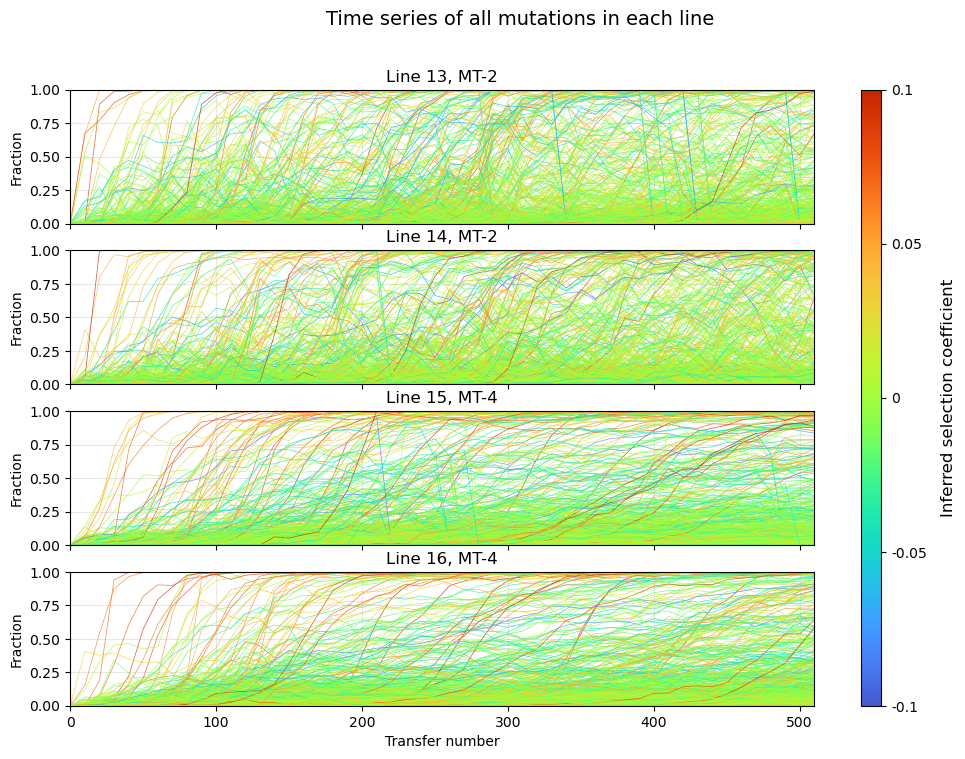

In [9]:
#Plot processed time series
fig, axes = plt.subplots(4,1,figsize=(12,8),sharex=True)
cmap = plt.get_cmap('turbo')
colors = cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mcolors.ListedColormap(colors)
norm = mcolors.Normalize(vmin=-0.1, vmax=0.1)

#Plot time series
for i,ax in enumerate(axes):

    #Get line data
    data_line = data[data['line']==i+13]
    # data_line = data_line[data_line['type'] == 'substitution'] #'substitution', 'insertion', 'deletion'

    #Find colours
    s_all = data_line.loc[data_line['line']==i+13,'s']
    colours = [new_cmap(norm(s)) for s in s_all]

    #Plot 
    data_line[np.arange(0,511,10)].T.plot(ax=ax, color=colours, linewidth=0.5, legend=False, alpha=0.8) 

    #Format
    ax.grid(alpha=0.3)
    ax.set_xlabel('Transfer number')
    ax.set_ylabel('Fraction')
    ax.set_title(f'Line {i+13}, MT-{(np.floor(i/2)*2 +2).astype(int)}')
    ax.set_xlim(0,51)
    ax.set_ylim(0,1)

#Colorbar
sm = plt.cm.ScalarMappable(cmap=new_cmap, norm=norm)
sm.set_array([]) 
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), pad=0.05, aspect=30)
cbar.set_label('Inferred selection coefficient', fontsize=12, labelpad=10)
cbar.set_ticks([-0.1, -0.05, 0, 0.05, 0.1])
cbar.ax.set_yticklabels([-0.1, -0.05, 0, 0.05, 0.1])

fig.suptitle('Time series of all mutations in each line',fontsize=14)
plt.savefig(fig_path + "/mutation_time_series_s.pdf", bbox_inches="tight")
plt.show()

## Plot DFEs

In [10]:
method = '' #'' or ' no linkage'

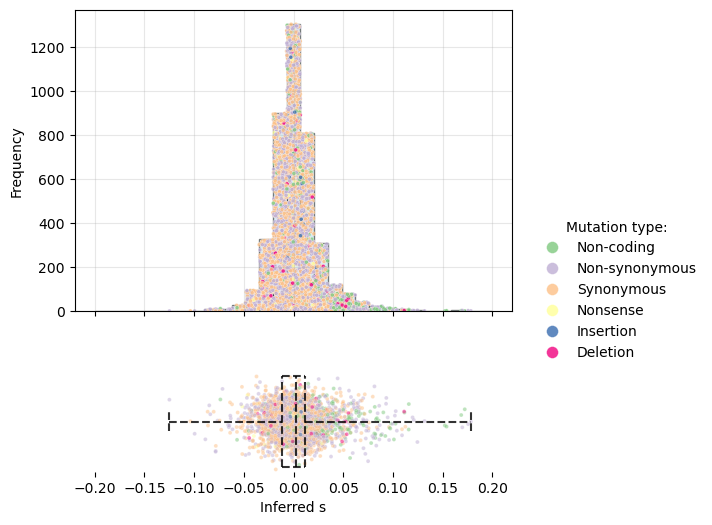

In [ ]:
#Plot combined DFE
fig, (ax_hist,ax_box) = plt.subplots(2,1,figsize=(7,6),sharex=True,gridspec_kw={'height_ratios': [3,1]})

cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))


#Histogram
muts_data = data.copy()
counts = ax_hist.hist(muts_data['s'+method],bins=np.linspace(-0.2,0.2,30),alpha=0.5,edgecolor='black',facecolor='lightblue')
muts_data['y_jitter'] = np.zeros(len(muts_data))
for i in range(len(counts[0])):
    muts_data.loc[(muts_data['s'+method]>counts[1][i]) & (muts_data['s'+method]<=counts[1][i+1]),'y_jitter'] = np.random.uniform(0, counts[0][i], size=counts[0][i].astype(int))
sns.scatterplot(data=muts_data, x='s'+method, y='y_jitter', ax=ax_hist,alpha=0.8,s=8,hue='muttype',palette=colors,edgecolor="white",legend=True)


#Box plot
sns.scatterplot(data=muts_data, x='s'+method, y=np.random.normal(0.5, 0.15, size=len(muts_data)), ax=ax_box,alpha=0.5,s=8,hue='muttype',palette=colors,edgecolor="white",legend=False)
mean = muts_data['s'+method].mean()      
q1 = np.percentile(muts_data['s'+method],25)
q2 = np.percentile(muts_data['s'+method],75)

ax_box.plot(np.zeros(5)+mean,np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax_box.plot(q1+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax_box.plot(q2+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax_box.plot(np.linspace(q1,q2,5),np.zeros(5),'--',color='black',alpha=0.8)
ax_box.plot(np.linspace(q1,q2,5),np.zeros(5)+1,'--',color='black',alpha=0.8)
ax_box.plot(np.linspace(q2,muts_data['s'+method].max(),5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax_box.plot(np.linspace(muts_data['s'+method].min(),q1,5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax_box.plot(muts_data['s'+method].max()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)
ax_box.plot(muts_data['s'+method].min()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)

# ax_box.text(-0.2,0.9,f'Mean = {mean:.4f}')


#Format
ax_box.spines[['left','right','top','bottom']].set_visible(False)
ax_box.set_yticks(ticks=[],labels=[])
ax_box.set_ylim(-0.05,1.05)

handles, labels = ax_hist.get_legend_handles_labels()
ax_hist.get_legend().remove()
ax_hist.grid(alpha=0.3)

ax_box.set_xlabel('Inferred s')
ax_hist.set_ylabel('Frequency')

fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.9, 0.55), ncol=1, title='Mutation type:', frameon=False, markerscale=3)
plt.subplots_adjust(right=0.75, hspace=0.3, wspace=0.2)
# plt.suptitle(f'Distribution of inferred selection coefficients,{method}',fontsize=16)
plt.savefig(fig_path + f"/DFE_combined{method}.pdf", bbox_inches='tight')
plt.show()

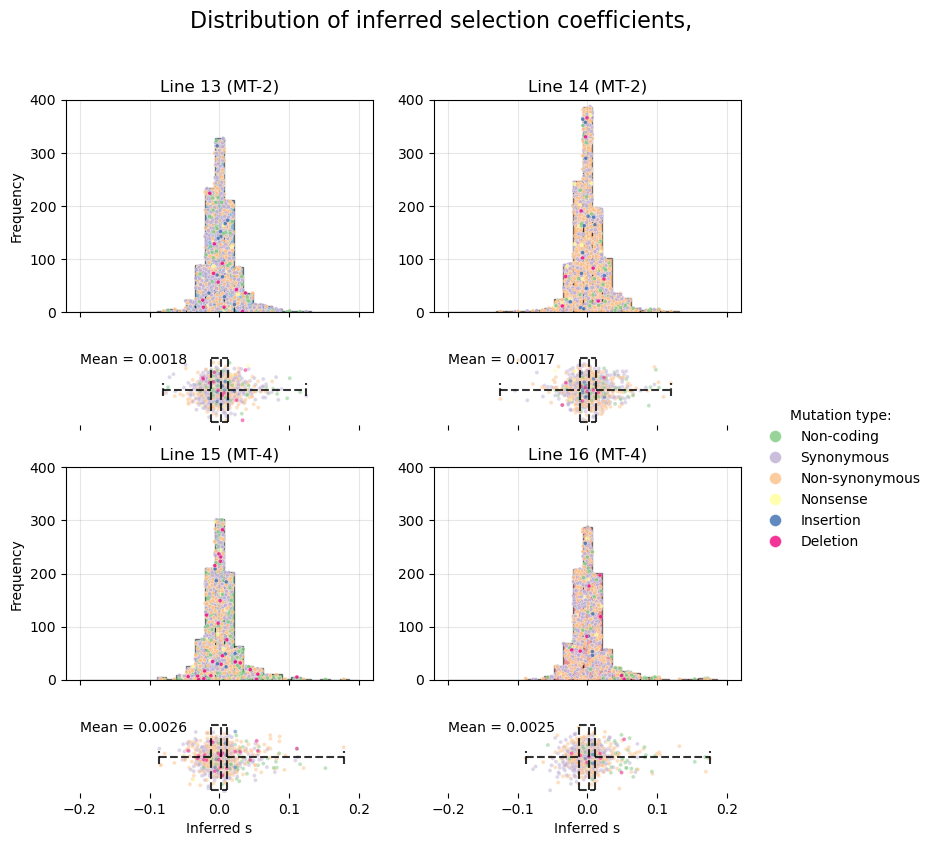

In [12]:
#Plot DFEs
fig, axes = plt.subplots(4,2,figsize=(10,9),sharex=True,gridspec_kw={'height_ratios': [3, 1,3,1]})
axes = axes.flatten()
hist_idx = [0,1,4,5]
box_idx = [2,3,6,7]
cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))
line_colours = ['tab:blue','tab:orange','tab:green','tab:red']

for j in range(4):
    ax_hist = axes[hist_idx[j]]
    ax_box = axes[box_idx[j]]

    #Get line data
    muts_line = data[data['line']==j+13].copy()

    #Histogram
    counts = ax_hist.hist(muts_line['s'+method],bins=np.linspace(-0.2,0.2,30),alpha=0.5,edgecolor='black',facecolor=line_colours[j])
    muts_line['y_jitter'] = np.zeros(len(muts_line))
    for i in range(len(counts[0])):
        muts_line.loc[(muts_line['s'+method]>counts[1][i]) & (muts_line['s'+method]<=counts[1][i+1]),'y_jitter'] = np.random.uniform(0, counts[0][i], size=counts[0][i].astype(int))
    sns.scatterplot(data=muts_line, x='s'+method, y='y_jitter', ax=ax_hist,alpha=0.8,s=8,hue='muttype',palette=colors,edgecolor="white",legend=True)


    #Box plot
    sns.scatterplot(data=muts_line, x='s'+method, y=np.random.normal(0.5, 0.15, size=len(muts_line)), ax=ax_box,alpha=0.5,s=8,hue='muttype',palette=colors,edgecolor="white",legend=False)
    mean = muts_line['s'+method].mean()      
    q1 = np.percentile(muts_line['s'+method],25)
    q2 = np.percentile(muts_line['s'+method],75)

    ax_box.plot(np.zeros(5)+mean,np.linspace(0,1,5),'--',color='black',alpha=0.8)
    ax_box.plot(q1+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
    ax_box.plot(q2+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
    ax_box.plot(np.linspace(q1,q2,5),np.zeros(5),'--',color='black',alpha=0.8)
    ax_box.plot(np.linspace(q1,q2,5),np.zeros(5)+1,'--',color='black',alpha=0.8)
    ax_box.plot(np.linspace(q2,muts_line['s'+method].max(),5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
    ax_box.plot(np.linspace(muts_line['s'+method].min(),q1,5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
    ax_box.plot(muts_line['s'+method].max()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)
    ax_box.plot(muts_line['s'+method].min()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)

    ax_box.text(-0.2,0.9,f'Mean = {mean:.4f}')


    #Format
    ax_box.spines[['left','right','top','bottom']].set_visible(False)
    ax_box.set_yticks(ticks=[],labels=[])
    ax_box.set_ylim(-0.05,1.05)

    handles, labels = ax_hist.get_legend_handles_labels()
    ax_hist.get_legend().remove()
    ax_hist.set_ylabel("")
    ax_hist.grid(alpha=0.3)
    ax_hist.set_title(f'Line {j+13} (MT-{(np.floor(j/2)*2 +2).astype(int)})')
    ax_hist.set_ylim(0,400) #400 for '', 850 for ' no linkage'

    if j > 1:
        ax_box.set_xlabel('Inferred s')
    if j==0 or j==2:
        ax_hist.set_ylabel('Frequency')


fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.9, 0.55), ncol=1, title='Mutation type:', frameon=False, markerscale=3)
plt.subplots_adjust(right=0.8, hspace=0.3, wspace=0.2)
plt.suptitle(f'Distribution of inferred selection coefficients,{method}',fontsize=16)
plt.savefig(fig_path + f"/DFE_each_line{method}.pdf")
plt.show()

In [13]:
#Mann-Whitney U test for pairwaise comparison
group1 = data.loc[data['line']<15,'s'+method].values
group2 = data.loc[data['line']>14,'s'+method].values
# group1 = data.loc[data['line']==14,'s'+method].values
# group2 = data.loc[data['line']==15,'s'+method].values

stat, p_value = stats.mannwhitneyu(group1,group2,alternative='two-sided')
print(f"U-statistic: {stat}")
print(f"P-value: {p_value}")

U-statistic: 2081241.0
P-value: 0.975478874915164


No pairs are significantly different for MPL, and neither is MT2 vs. MT4.
All pairs significantly different for no linkage, except both MT2 lines.

## Comparison between MPL and no linkage method

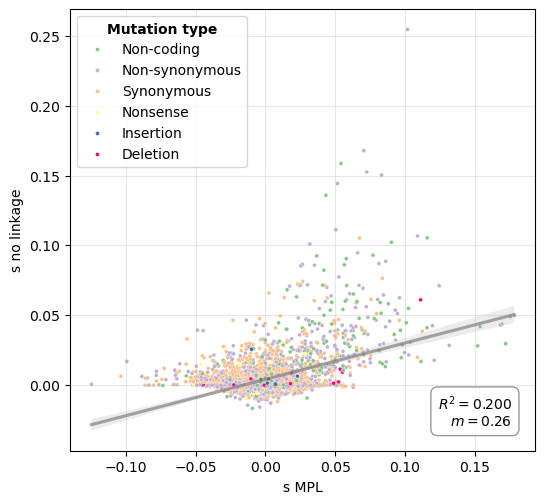

In [14]:
fig, ax = plt.subplots(1,1,figsize=(6,6))
cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))

#Plot
sns.regplot(data=data, x='s', y='s no linkage', scatter=False, line_kws={'alpha':0.7,'color':'grey'})
sns.scatterplot(data=data, x='s', y='s no linkage', hue='muttype',palette=colors,edgecolor="white",s=8,legend=True,ax=ax)
m,_,r,_,_ = stats.linregress(data['s'], data['s no linkage'])
ax.text(0.95,0.05,f'$R^2=${r**2:.3f}\n$m=${m:.2f}',transform=ax.transAxes,fontsize=10,verticalalignment="bottom",horizontalalignment="right",bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.8, edgecolor="gray"))

#Format
ax.set_aspect('equal')
ax.grid(alpha=0.3)
ax.set_xlabel('s MPL')
ax.legend(title='Mutation type', title_fontproperties={"weight": "bold"})
plt.savefig(fig_path + f"/MPL_against_no_linkage_scatter.pdf")
plt.show()

## Mutation and genotype fitness distributions over time

Choose mutations/genotype fitnesses at random (weighted by frequency) to plot histogram

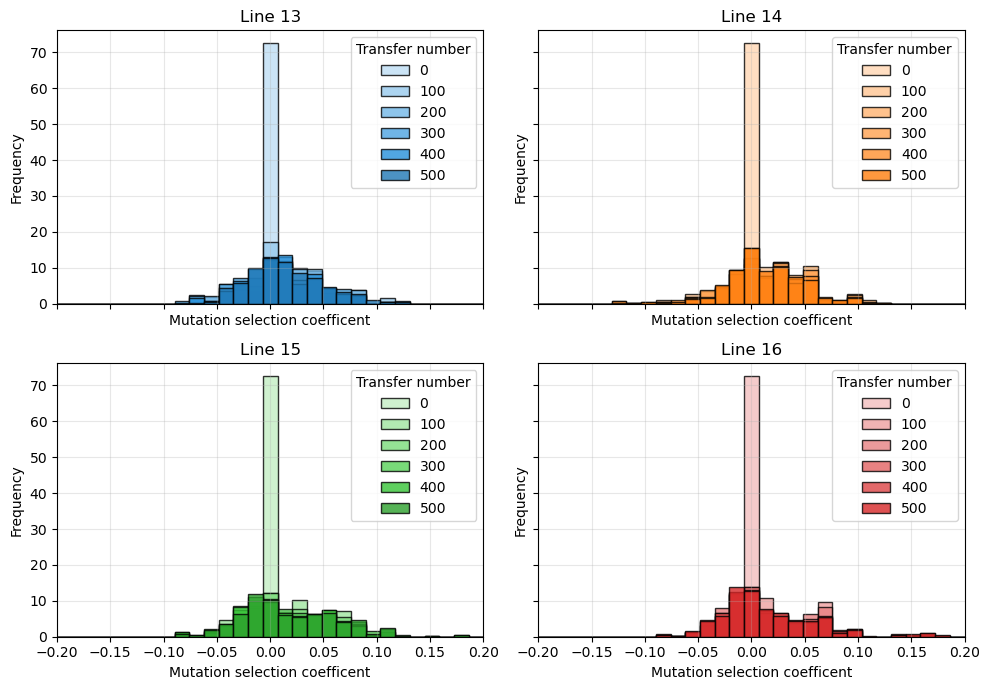

In [15]:
#Choose random genotype fitnesses
num_mutations = 1000
mutation_fitnesses = np.zeros((4,52,num_mutations))
for j,line in enumerate([13,14,15,16]):
    data_line = data[data['line']==line]
    for g in range(1,52):
        mutation_fitnesses[j,g,:] = np.random.choice(data_line['s'], size=num_mutations, p=data_line[g*10]/data_line[g*10].sum())

#Plot histograms
fig, axes = plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True)
axes = axes.flatten()
colours = ['tab:blue','tab:orange','tab:green','tab:red']

for j in range(4):
    h, l, s = colorsys.rgb_to_hls(*mcolors.to_rgb(colours[j]))
    for i,g in enumerate(range(0,52,10)):
        new_l = 0.85 - i*(0.85 - l)/5
        axes[j].hist(mutation_fitnesses[j,g,:],bins=np.linspace(-0.2,0.2,30),color=colorsys.hls_to_rgb(h, new_l, s), edgecolor='black',density=True,label=str(g*10),alpha=0.8)

    #Format
    axes[j].set_xlim(-0.2,0.2)
    axes[j].grid(alpha=0.3)
    axes[j].set_xlabel('Mutation selection coefficent')
    axes[j].set_ylabel('Frequency')
    axes[j].legend(title = 'Transfer number')
    axes[j].set_title(f'Line {j+13}')

plt.tight_layout()
plt.savefig(fig_path + f"/DFE_over_time_mutations.pdf")
plt.show()

In [16]:
#Choose random genotype fitnesses
num_genotypes = 1000
genotype_fitnesses = np.zeros((4,52,num_genotypes))
for j,line in enumerate([13,14,15,16]):
    data_line = data[data['line']==line]
    for g in range(52):
        for i in range(num_genotypes):
            mask = np.random.rand(len(data_line)) < data_line[g*10]
            genotype_fitnesses[j,g,i] = np.sum(data_line.loc[mask,'s'])

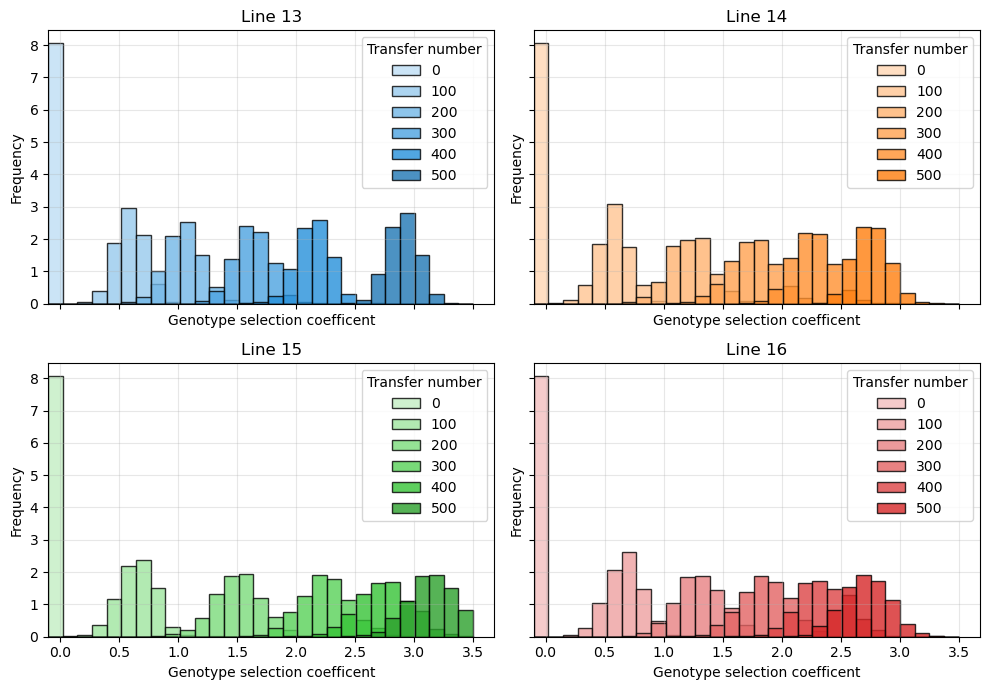

In [17]:
#Plot histograms
fig, axes = plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True)
axes = axes.flatten()

for j in range(4):
    h, l, s = colorsys.rgb_to_hls(*mcolors.to_rgb(colours[j]))
    for i,g in enumerate(range(0,52,10)):
        new_l = 0.85 - i*(0.85 - l)/5
        axes[j].hist(genotype_fitnesses[j,g,:],bins=np.linspace(-0.1,3.5,30),color=colorsys.hls_to_rgb(h, new_l, s), edgecolor='black',density=True,label=str(g*10),alpha=0.8)

    #Format
    axes[j].set_xlim(left=-0.1)
    axes[j].grid(alpha=0.3)
    axes[j].set_xlabel('Genotype selection coefficent')
    axes[j].set_ylabel('Frequency')
    axes[j].legend(title='Transfer number')
    axes[j].set_title(f'Line {j+13}')

plt.tight_layout()
plt.savefig(fig_path + f"/DFE_over_time_genotypes.pdf")
plt.show()

In [18]:
#Save MPL results
MPL_fitness_estimates = np.zeros((4,6))
MPL_std = np.zeros((4,6))

for j in range(4):
    for i,g in enumerate(range(0,52,10)):
        MPL_fitness_estimates[j,i] = genotype_fitnesses[j,g,:].mean()
        MPL_std[j,i] = genotype_fitnesses[j,g,:].std()

np.savez(out_path + '/MPL_results.npz', means = MPL_fitness_estimates, stds = MPL_std)

## Figure 1

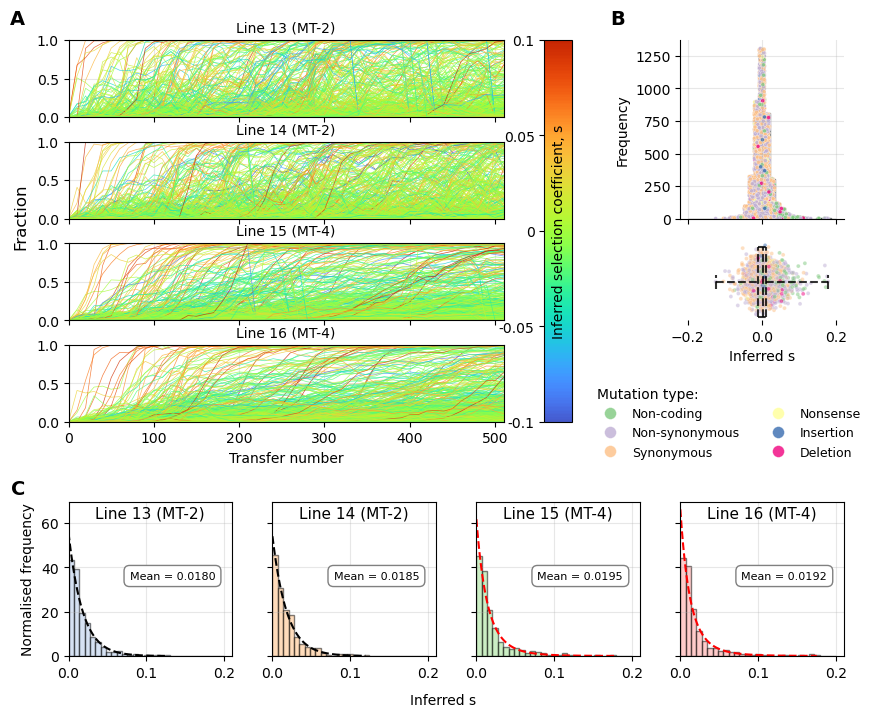

In [19]:
fig = plt.figure(figsize=(10, 8))

#Define grid
gs = fig.add_gridspec(nrows=6,ncols=12,height_ratios=[1,1,1,1,0.4,2],wspace=1.5,hspace=0.3)
ax1 = fig.add_subplot(gs[0, 0:7])
ax2 = fig.add_subplot(gs[1, 0:7])
ax3 = fig.add_subplot(gs[2, 0:7])
ax4 = fig.add_subplot(gs[3, 0:7])
cbar_ax = fig.add_subplot(gs[0:4, 7])
ax5 = fig.add_subplot(gs[0:2, 9:12]) 
ax6 = fig.add_subplot(gs[2, 9:12]) 
ax7 = fig.add_subplot(gs[3, 9:12]) 
ax8 = fig.add_subplot(gs[5, 0:3])
ax9 = fig.add_subplot(gs[5, 3:6])
ax10 = fig.add_subplot(gs[5, 6:9])
ax11 = fig.add_subplot(gs[5, 9:12])

ax9.sharey(ax8)
ax10.sharey(ax8)
ax11.sharey(ax8)

#Trajectories plot
cmap = plt.get_cmap('turbo')
colors = cmap(np.linspace(0.1, 0.9, 256))
new_cmap = mcolors.ListedColormap(colors)
norm = mcolors.Normalize(vmin=-0.1, vmax=0.1)

for i,ax in enumerate([ax1,ax2,ax3,ax4]):

    #Get line data
    data_line = data[data['line']==i+13]

    #Find colours
    s_all = data_line.loc[data_line['line']==i+13,'s']
    colours = [new_cmap(norm(s)) for s in s_all]

    #Plot 
    data_line[np.arange(0,511,10)].T.plot(ax=ax, color=colours, linewidth=0.5, legend=False, alpha=0.8) 

    #Format
    ax.grid(alpha=0.3)
    if i<3:
        ax.set_xticklabels([])
    ax.set_title(f'Line {i+13} (MT-{(np.floor(i/2)*2 +2).astype(int)})',fontsize=10)
    ax.set_xlim(0,51)
    ax.set_ylim(0,1)

ax4.set_xlabel('Transfer number')
fig.text(0.07, 0.66, 'Fraction', va='center', rotation='vertical', fontsize=12)
ax1.text(-0.1, 1.4, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Colorbar
sm = plt.cm.ScalarMappable(cmap=new_cmap, norm=norm)
sm.set_array([]) 
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_ticks([-0.1, -0.05, 0, 0.05, 0.1])
cbar.set_ticklabels([-0.1, -0.05, 0, 0.05, 0.1])
cbar.ax.yaxis.set_ticks_position('left')
cbar.ax.yaxis.set_label_position('left')
cbar_ax.text(0.55,0.5,'Inferred selection coefficient, s',transform=cbar_ax.transAxes,ha='center',va='center',color='black',fontsize=10,rotation=90)

#DFE Histogram
cmap = plt.colormaps['Accent']
colors = list(cmap(np.linspace(0, 0.7, 6)))
muts_data = data.copy()
counts = ax5.hist(muts_data['s'+method],bins=np.linspace(-0.2,0.2,30),alpha=0.5,edgecolor='black',facecolor='lightblue')
muts_data['y_jitter'] = np.zeros(len(muts_data))
for i in range(len(counts[0])):
    muts_data.loc[(muts_data['s'+method]>counts[1][i]) & (muts_data['s'+method]<=counts[1][i+1]),'y_jitter'] = np.random.uniform(0, counts[0][i], size=counts[0][i].astype(int))
sns.scatterplot(data=muts_data, x='s'+method, y='y_jitter', ax=ax5,alpha=0.8,s=8,hue='muttype',palette=colors,edgecolor="white",legend=True)

ax5.get_legend().remove()
ax5.set_ylabel("")
ax5.grid(alpha=0.3)
ax5.set_ylabel('Frequency')
ax5.tick_params(labelbottom=False)
ax5.set_xlabel('')
ax5.spines[['right','top']].set_visible(False)
ax5.text(1.28, 1.4, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#DFE Box plot
sns.scatterplot(data=muts_data, x='s'+method, y=np.random.normal(0.5, 0.15, size=len(muts_data)), ax=ax6,alpha=0.5,s=8,hue='muttype',palette=colors,edgecolor="white",legend=False)
mean = muts_data['s'+method].mean()      
q1 = np.percentile(muts_data['s'+method],25)
q2 = np.percentile(muts_data['s'+method],75)

ax6.plot(np.zeros(5)+mean,np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax6.plot(q1+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax6.plot(q2+np.zeros(5),np.linspace(0,1,5),'--',color='black',alpha=0.8)
ax6.plot(np.linspace(q1,q2,5),np.zeros(5),'--',color='black',alpha=0.8)
ax6.plot(np.linspace(q1,q2,5),np.zeros(5)+1,'--',color='black',alpha=0.8)
ax6.plot(np.linspace(q2,muts_data['s'+method].max(),5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax6.plot(np.linspace(muts_data['s'+method].min(),q1,5),0.5+np.zeros(5),'--',color='black',alpha=0.8)
ax6.plot(muts_data['s'+method].max()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)
ax6.plot(muts_data['s'+method].min()+np.zeros(5),np.linspace(0.4,0.6,5),'--',color='black',alpha=0.8)

ax6.spines[['left','right','top','bottom']].set_visible(False)
ax6.set_yticks(ticks=[],labels=[])
ax6.set_ylim(-0.05,1.05)
ax6.set_xlabel('Inferred s')
ax6.sharex(ax5)

#DFE legend
handles, labels = ax5.get_legend_handles_labels()
ax7.legend(handles, labels, loc='upper center' , ncols=2, title='Mutation type:', frameon=False, markerscale=3,fontsize=9,title_fontsize=10,alignment='left',bbox_to_anchor=(0.3,0.6))
ax7.axis('off')


#Beneficial tails
axes = [ax8,ax9,ax10,ax11]
cmap = plt.get_cmap('tab20')
colours = [cmap(i)[:3] for i in range(20)]

for j,ax in enumerate(axes):
    #Get beneficial tail
    data_line = data[data['line']==j+13].copy()
    s_line = data_line['s']
    s_ben_line = s_line[s_line>0]
    ax.hist(s_ben_line, density=True, bins=np.linspace(0,0.2,30),alpha=0.5,edgecolor='black',facecolor=colours[1+2*j], label='Inferred beneficial tail')
    
    #Plot best fit line
    x = np.linspace(0, max(s_ben_line), 100)
    if j < 2:
        #Fit exponential model, pdf = 1/l exp(-x/l)
        _, l_fit = expon.fit(s_ben_line, floc=0) 
        ax.plot(x, expon.pdf(x, 0, l_fit), '--', color='black', label=f'Exponential model, \nscale parameter = {l_fit:.3f}')
    

    else:
        #Fit generalised pareto model, pdf = (1/t)((1+kx/t)**(-(k+1)/k))
        k_fit, _, t_fit = genpareto.fit(s_ben_line, floc=0) 
        ax.plot(x, genpareto.pdf(x, k_fit, 0, t_fit), '--', color='red', label=f'GPM, \nk parameter = {k_fit:.3f}, \nscale parameter = {t_fit:.3f}')

    #Plot mean
    ax.text(0.9,0.5,f'Mean = {s_ben_line.mean():.4f}',fontsize=8,bbox=dict(facecolor='white', edgecolor='grey', boxstyle='round,pad=0.5'),transform=ax.transAxes, ha='right')

    #Format
    ax.text(0.5,0.9,f'Line {j+13} (MT-{(np.floor(j/2)*2 +2).astype(int)})',transform=ax.transAxes, ha='center',fontsize=11)
    ax.grid(alpha=0.3)
    ax.set_xlim(left=0)

fig.text(0.5,0.05,'Inferred s',ha='center',fontsize=10)
ax8.set_ylabel('Normalised frequency')
ax8.text(-0.1, -4.7, 'C', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.savefig(fig_path+'/Figure_1.pdf')
plt.show()